### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}]
    
}

In [11]:
# Define the filter criteria
'''filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "25/5 eval freezing enc, modalities, n of examples",
    "config.seed" : 420,
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
}'''


'filter_criteria = {\n    \'config.image_encoder.use\': True,\n    #\'config.tabular_encoder.use\': True,\n    #\'config.loc_encoder.use\': True,\n    \n    "group" : "25/5 eval freezing enc, modalities, n of examples",\n    "config.seed" : 420,\n    "$or": [{\n        \'config.train_examples_per_class\': {\n            "$gt": \'200\',\n        }\n    },\n        {\n        \'config.train_examples_per_class\': {\n            "$lt": \'200\',\n        }\n    }\n    ]\n}'

In [54]:
# Define the filter criteria
filter_criteria = {
    #'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    

    #"group" : "5/8 test set one image",
    "group" : "25/9 loc encoder sirent + PE",
    #"group" : "11/9 loc encoders",

    #"config.seed" : 420,
    #"$and": [{
    #'created_at': {
    #        "$lt": '2024-09-26T00',
    #        "$gt": '2024-09-24T00'
    #    }
    #}]

    
}





In [55]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 15


In [56]:
#models = models[:15]

In [57]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#models = [model for model in models  if model['config']['seed'] == 422]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [58]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
assert device == 'cuda'
n_classes = 11


In [59]:
CHECKPOINT_TYPE = 'last'

for i, model_dict in enumerate(tqdm.tqdm(models)):
    #if i < 16:
    #    continue
    #if i > 2:
    #    break
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = None
    
    try:
        metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
    except Exception as e:
        print(e)
        continue
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #try:
    #    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])
    #    model_dict['summary']['val conf matrix'] = None
    #    model_dict['summary']['train conf matrix'] = None
    #except KeyError:
    #    pass
    

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [05:07<00:00, 20.53s/it]


In [60]:
##### selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


In [61]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [62]:

#filename = '26_7_eval_on_test_set'

#filename = '29_7_eval_on_test_set'
#filename_2 = '30_7_eval_on_test_set'
#filename = '30_7_eval_on_test_set_seed_422to425'
#filename = '5_8_eval_on_test_set_one_img'
#filename = '8_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_four_img'
filename = '12_9_loc_enc_all_modalities'

In [63]:
siren_models = models

In [64]:
for model in siren_models:
    print(model['config']['loc_encoder'])

{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'cartesian3d'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'wrap'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'direct'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'cartesian3d'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'wrap'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'direct'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'cartesian3d'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'wrap'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'direct'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'cartesian3d'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'wrap'}
{'nn': 'siren', 'use': True, 'num_layers': 2, 'positional_embedding': 'direct'}
{'nn': 'siren', 'use': True,

In [14]:
with open(f'{filename}.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [65]:
#name = "23_siren"


with open(f'{filename}.pickle', 'rb') as handle:
    other_models = pickle.load(handle)


In [66]:
len(other_models)

55

In [67]:
models = other_models + siren_models 

In [157]:
#models = [model for model in other_models  if model['config']['two_model_regularization']['use'] == False]
#models = [model for model in models  if model['config']['model_version'] == 'v1']




In [68]:
models_ = [model for model in models if model['config'] != {}]
models__ = [model for model in models_ if 'metrics' in model.keys()]


In [50]:
"""for model in models:
    if 'type' in model['config']['loc_encoder']:
        model['config']['loc_encoder']['nn'] = model['config']['loc_encoder'].pop('type')

for model in models:
    if model['config']['loc_encoder']['nn'] == 'siren':
        #print(model['config']['loc_encoder'])
        model['config']['loc_encoder']['positional_embedding'] = 'none'
for model in models:
    
    if model['config']['loc_encoder']['nn'] != 'siren':
        #print(model['config']['loc_encoder'])
        model['config']['loc_encoder']['num_layers'] = 'none'
"""

In [69]:
_models = [model for model in models if 'positional_embedding' in model['config']['loc_encoder'].keys()]

___models = [model for model in _models if model['config']['loc_encoder']['positional_embedding'] in  ['direct', 'wrap', 'cartesian3d']]


models = ___models


In [70]:
for model in ___models:
    print(model['config']['loc_encoder'])

{'nn': 'linear', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'wrap'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'wrap'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'direct'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'direct'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'wrap'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'wrap'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'direct'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'direct'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'fcnet', 'use': True, 'positional_embedding': 'cartesian3d'}
{'nn': 'linear', 'use': True, 'positional_embedding': 'wrap'}
{'nn': 'fcnet', 'use': True

In [71]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [72]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [73]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'loc_encoder': {'nn': ['fcnet', 'siren', 'linear'],
  'positional_embedding': ['direct', 'cartesian3d', 'wrap']}}

In [74]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [75]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [76]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [32]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [77]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        #assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue

    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = concat_df['accuracy']


        

In [78]:
data = {}
for k,v in performance_per_configuration.items():
    print(v)
    data[k] = [v[i]['support'] for i in range(5)]

0  precision    0.862461
   recall       0.862461
   f1-score     0.862461
   support      0.862461
1  precision    0.871714
   recall       0.871714
   f1-score     0.871714
   support      0.871714
2  precision    0.854259
   recall       0.854259
   f1-score     0.854259
   support      0.854259
3  precision    0.845216
   recall       0.845216
   f1-score     0.845216
   support      0.845216
4  precision    0.878023
   recall       0.878023
   f1-score     0.878023
   support      0.878023
Name: accuracy, dtype: float64
0  precision    0.867087
   recall       0.867087
   f1-score     0.867087
   support      0.867087
1  precision    0.875499
   recall       0.875499
   f1-score     0.875499
   support      0.875499
2  precision    0.850894
   recall       0.850894
   f1-score     0.850894
   support      0.850894
3  precision    0.858465
   recall       0.858465
   f1-score     0.858465
   support      0.858465
4  precision    0.863302
   recall       0.863302
   f1-score     0.8

In [79]:
for k,v in data.items():
    if 'theory' in k:
        continue
    print(k, (sum(v) / len(v)))

{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'direct'}} 0.8623343848580441
{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'cartesian3d'}} 0.8630494216614091
{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'wrap'}} 0.8714616193480547
{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'direct'}} 0.8583806519453209
{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'cartesian3d'}} 0.8720925341745531
{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'wrap'}} 0.8557728706624607
{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'direct'}} 0.8577497371188223
{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'cartesian3d'}} 0.8576656151419559
{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'wrap'}} 0.8692323869610936


In [ ]:
names = [
 
]

In [94]:
renamed_data = {
    'FCnet, Direct' : data["{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'direct'}}"],
    'FCnet, Cartesian3D': data["{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'cartesian3d'}}"],
    'FCnet, Wrap': data["{'loc_encoder': {'nn': 'fcnet', 'positional_embedding': 'wrap'}}"],
    'Siren, Direct': data["{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'direct'}}"],
    'Siren, Cartesian3D': data["{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'cartesian3d'}}"],
    'Siren, Wrap': data["{'loc_encoder': {'nn': 'siren', 'positional_embedding': 'wrap'}}"],
    'Linear, Direct': data["{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'direct'}}"],
    'Linear, Cartesian3D': data["{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'cartesian3d'}}"],
    'Linear, Wrap': data["{'loc_encoder': {'nn': 'linear', 'positional_embedding': 'wrap'}}"],   
}

/tmp/ipykernel_886223/2222521127.py:23: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  sig_colors = pval_matrix.applymap(lambda p: 0 if p < 0.05 else 1)


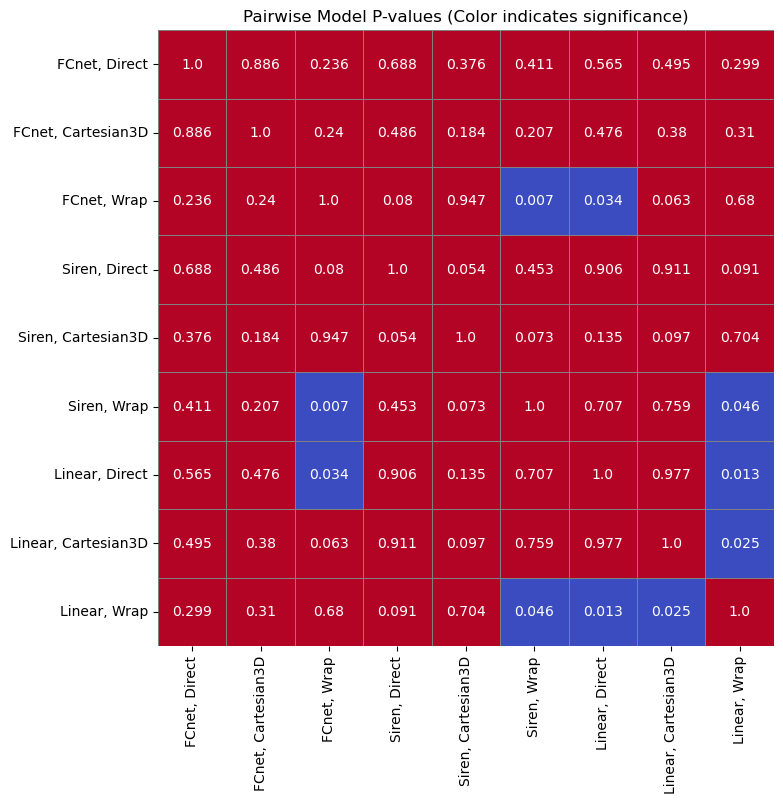

In [96]:
import scipy.stats as stats
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Example input (replace with actual data)
model_accuracies = renamed_data
model_names = list(model_accuracies.keys())
n = len(model_names)

# Initialize p-value matrix
pval_matrix = pd.DataFrame(np.ones((n, n)), index=model_names, columns=model_names)

# Perform paired t-tests
for (name1, acc1), (name2, acc2) in itertools.combinations(model_accuracies.items(), 2):
    t_stat, p_val = stats.ttest_rel(acc1, acc2)
    pval_matrix.loc[name1, name2] = p_val
    pval_matrix.loc[name2, name1] = p_val

# Define color mapping based on significance
sig_colors = pval_matrix.applymap(lambda p: 0 if p < 0.05 else 1)

# Visualize
plt.figure(figsize=(10, 8))
sns.heatmap(sig_colors, annot=pval_matrix.round(3), fmt='', cmap='coolwarm', cbar=False,
            square=True, linewidths=0.5, linecolor='gray', xticklabels=True, yticklabels=True)
#plt.title('Pairwise Model P-values (Color indicates significance)')
plt.title('Pairwise t-test')
plt.show()


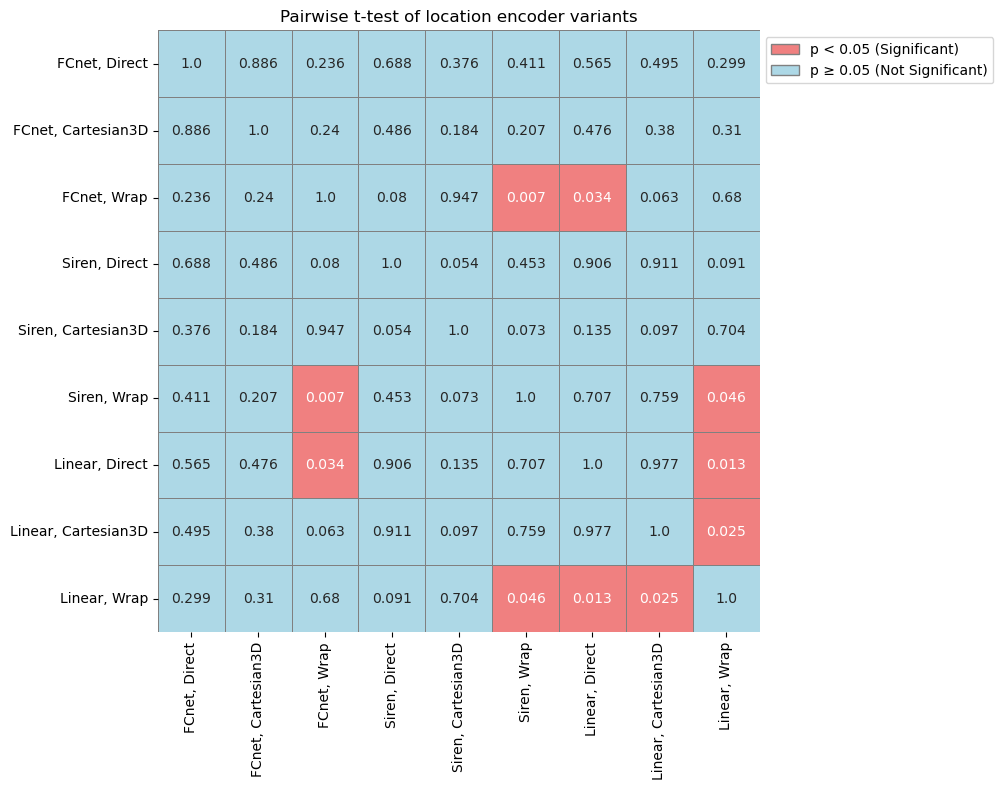

In [101]:
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

# Define a colormap and normalization for two discrete values: significant (0), not significant (1)
cmap = mcolors.ListedColormap(['lightcoral', 'lightblue'])
bounds = [-0.5, 0.5, 1.5]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(sig_colors, annot=pval_matrix.round(3), fmt='', cmap=cmap, norm=norm,
            cbar=False, square=True, linewidths=0.5, linecolor='gray',
            xticklabels=True, yticklabels=True)

# Add custom legend
legend_elements = [
    Patch(facecolor='lightcoral', edgecolor='gray', label='p < 0.05 (Significant)'),
    Patch(facecolor='lightblue', edgecolor='gray', label='p ≥ 0.05 (Not Significant)')
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.4, 1))
plt.title('Pairwise t-test of location encoder variants')
plt.tight_layout()
plt.show()


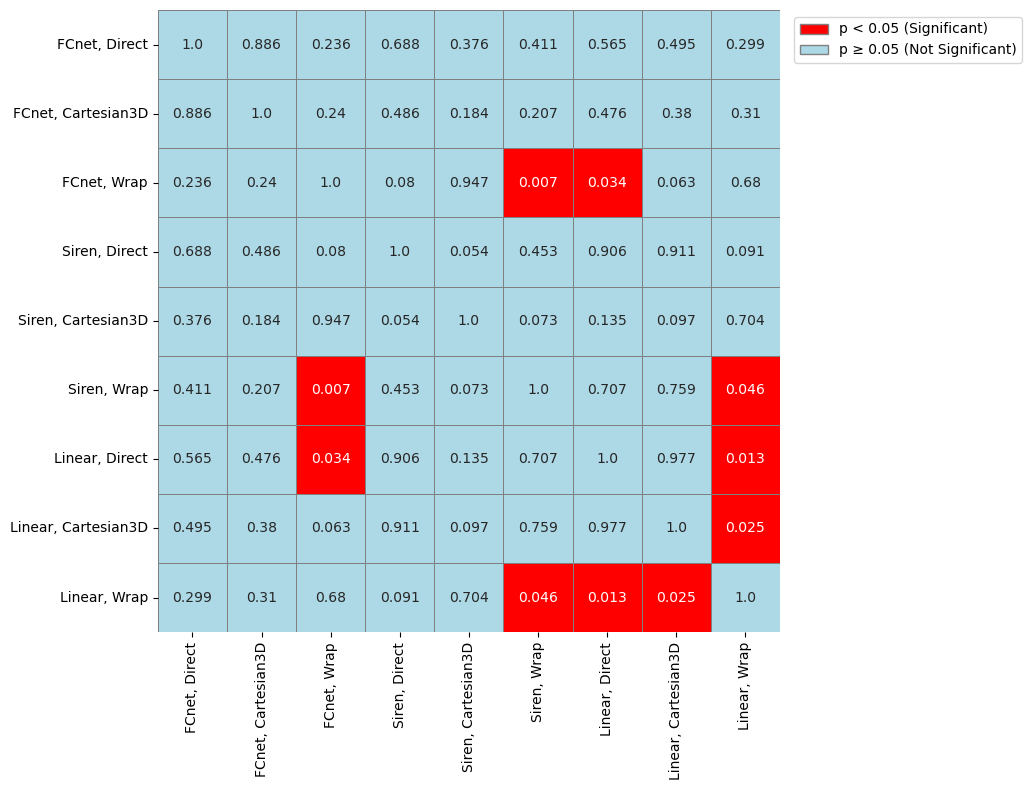

In [110]:
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

col_pos = 'red'
col_neg = 'lightblue'

# Define a colormap and normalization for two discrete values: significant (0), not significant (1)
cmap = mcolors.ListedColormap([col_pos, col_neg])
bounds = [-0.5, 0.5, 1.5]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(sig_colors, annot=pval_matrix.round(3), fmt='', cmap=cmap, norm=norm,
            cbar=False, square=True, linewidths=0.5, linecolor='gray',
            xticklabels=True, yticklabels=True)

# Add custom legend
legend_elements = [
    Patch(facecolor=col_pos, edgecolor='gray', label='p < 0.05 (Significant)'),
    Patch(facecolor=col_neg, edgecolor='gray', label='p ≥ 0.05 (Not Significant)')
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.4, 1))
#plt.title('Pairwise t-test of accuracies obtained with location encoder variants')
plt.tight_layout()
#plt.show()
plt.savefig("../paper/t_test_loc_encoder.png", dpi=300, bbox_inches='tight', transparent=True)


In [46]:
performance_per_configuration["{'loc_encoder': {'nn': 'siren', 'num_layers': 1, 'positional_embedding': 'none'}, 'seed': 425}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.861960,0.608757,0.842723,0.596538,0.781386,0.802975,0.946810,0.958139,0.819076,0.979494,0.831454,0.85266,0.820847,0.85157,0.478189
precision,0.840874,0.676625,0.834703,0.579529,0.750388,0.870944,0.947303,0.938353,0.846307,0.987583,0.852278,0.85266,0.829535,0.85648,0.478189
recall,0.886256,0.566507,0.855782,0.617172,0.826442,0.746617,0.948263,0.979155,0.800000,0.972242,0.813054,0.85266,0.819226,0.85266,0.478189
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.85266,4755.000000,4755.00000,0.478189


In [48]:
performance_per_configuration["{'loc_encoder': {'nn': 'siren', 'num_layers': 1, 'positional_embedding': 'none'}, 'seed': 425}"]['std']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.017679,0.015185,0.023172,0.097711,0.052725,0.035623,0.016850,0.018958,0.085391,0.025676,0.014276,0.018371,0.020205,0.018447,0.047954
precision,0.046135,0.105089,0.030150,0.087545,0.105779,0.049830,0.046313,0.012007,0.080279,0.006882,0.032010,0.018371,0.022828,0.019286,0.047954
recall,0.024740,0.059434,0.074530,0.113799,0.050234,0.045101,0.024813,0.032241,0.117752,0.044902,0.031161,0.018371,0.019814,0.018371,0.047954
support,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.018371,0.000000,0.000000,0.047954


In [40]:
no_theory = {key:value for key, value in performance_per_configuration.items() if 'theory' not in key} 

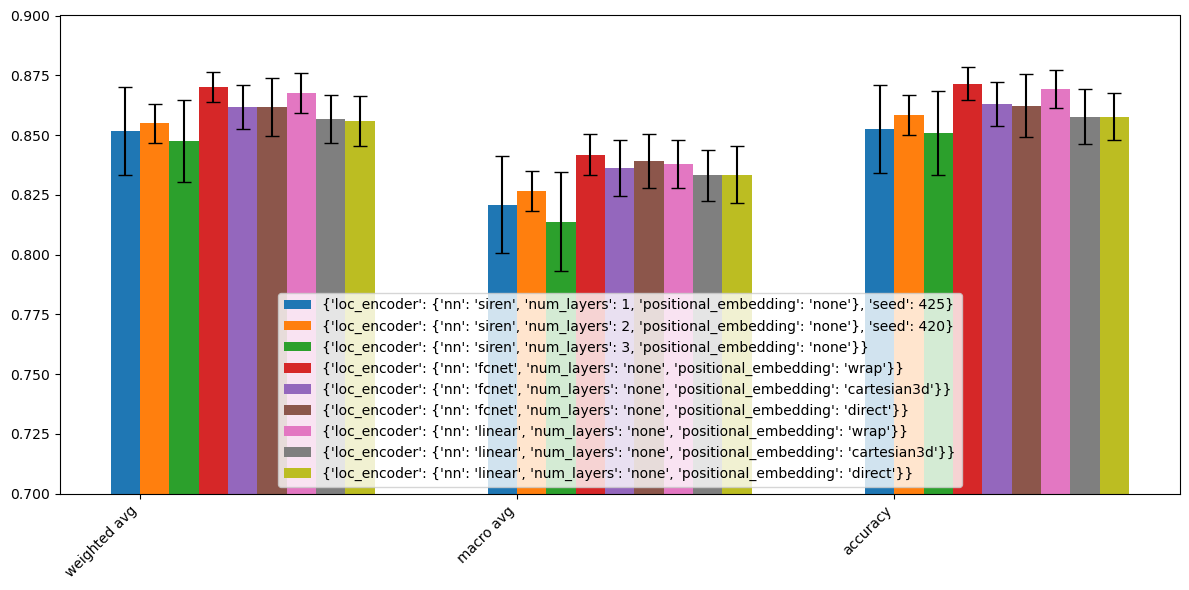

In [41]:
plot_metrics(no_theory, ylim=(0.7, 0.9))

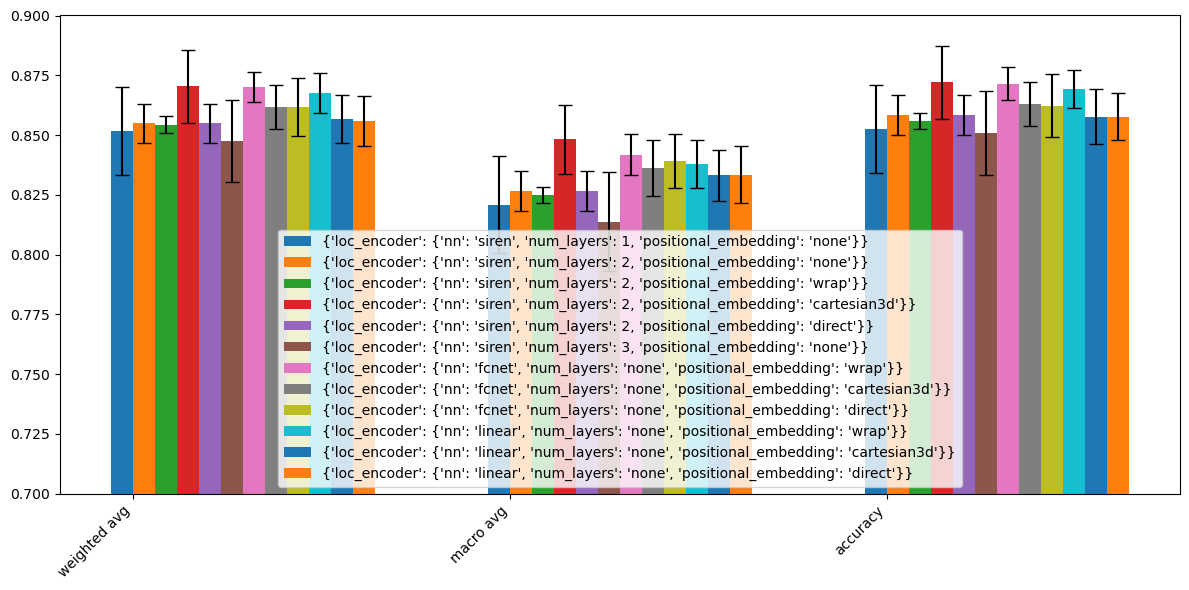

In [37]:
plot_metrics(no_theory, ylim=(0.7, 0.9))

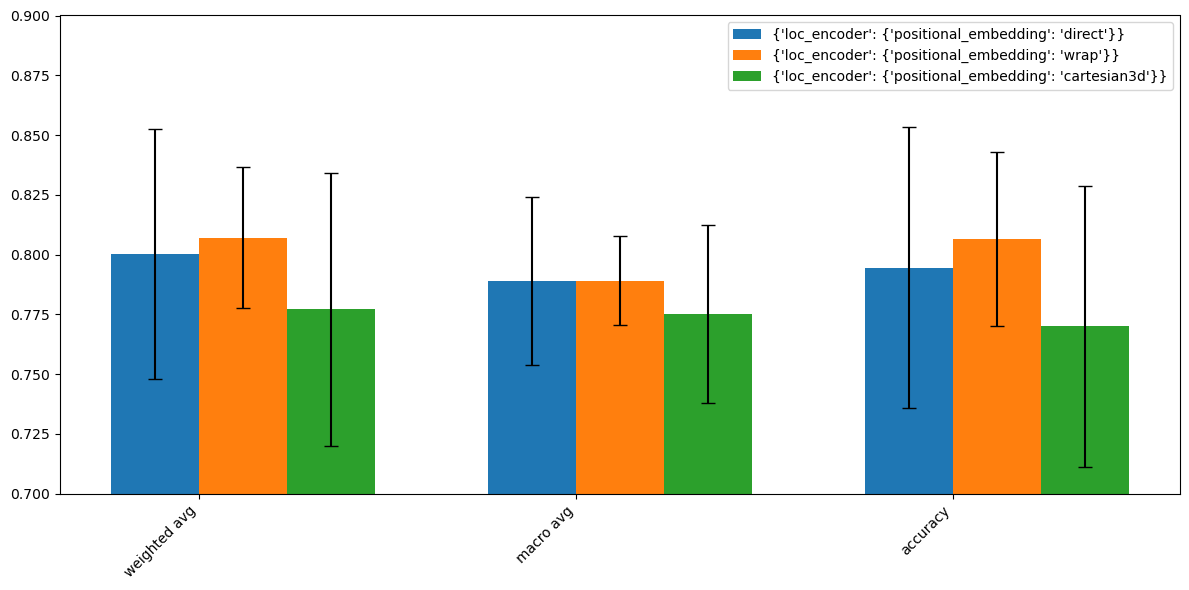

In [65]:
plot_metrics(performance_per_configuration, ylim=(0.7, 0.9))

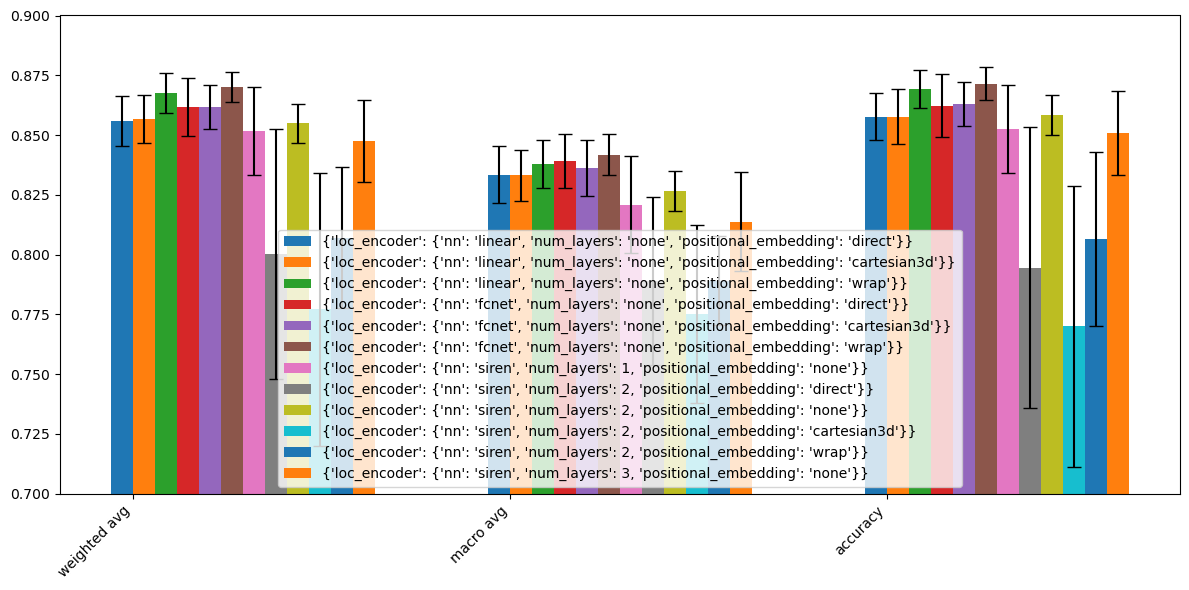

In [53]:
plot_metrics(performance_per_configuration, ylim=(0.7, 0.9))

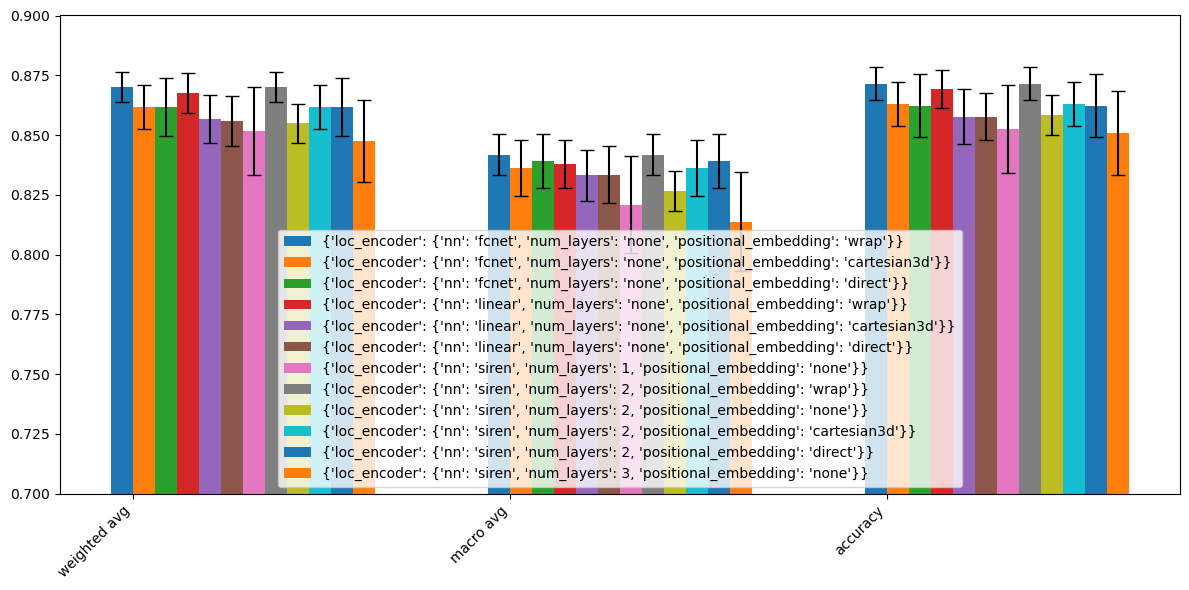

In [68]:
plot_metrics(no_theory, ylim=(0.7, 0.9))

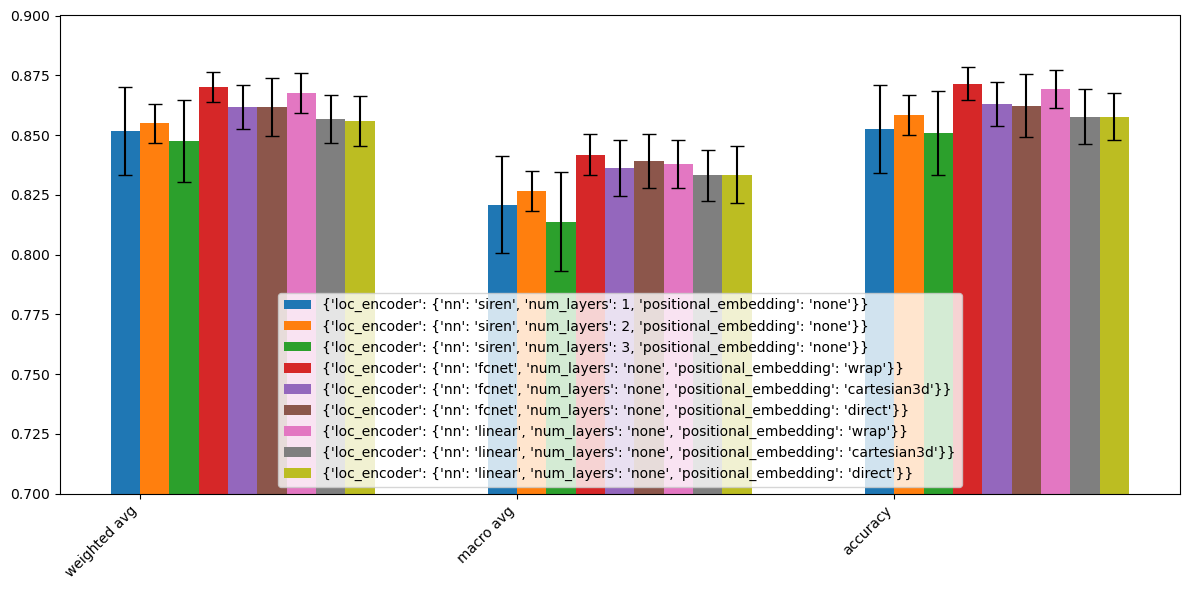

In [25]:
plot_metrics(no_theory, ylim=(0.7, 0.9))

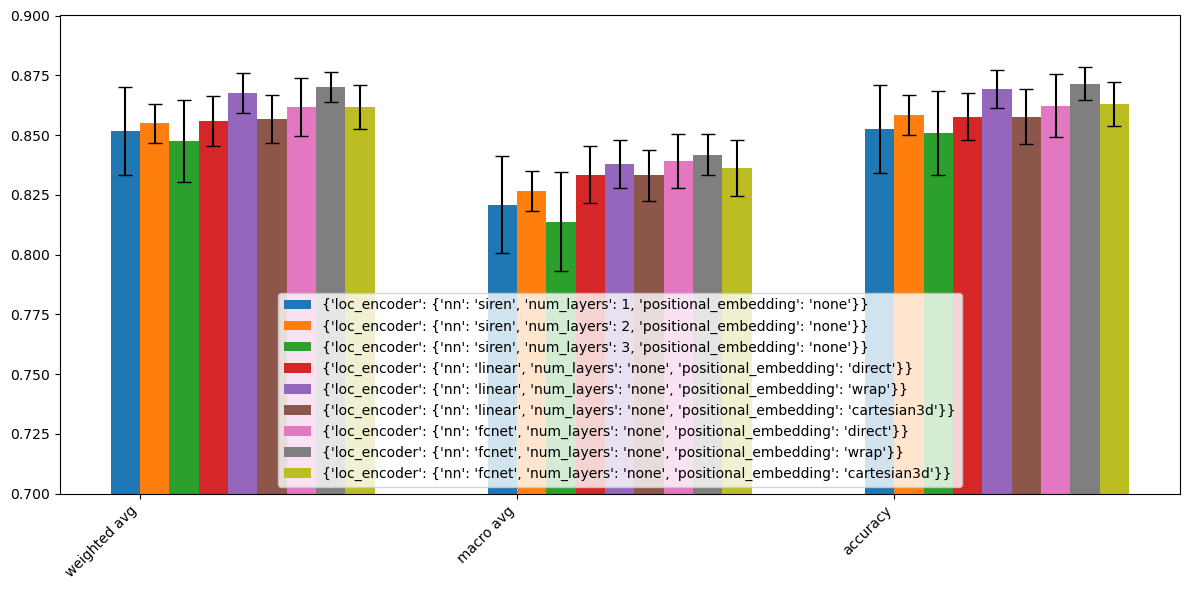

In [40]:
plot_metrics(no_theory, ylim=(0.7, 0.9))

In [69]:
loc_encoder_comparison = {}
for key, values in no_theory.items():

    loc_encoder_comparison[key] = {}
    loc_encoder_comparison[key]['acc'] = values['mean']['accuracy']['f1-score']
    loc_encoder_comparison[key]['macro avg'] = values['mean']['macro avg']['f1-score']
    loc_encoder_comparison[key]['weighted avg'] = values['mean']['weighted avg']['f1-score']
    
    #loc_encoder_comparison[key]['std_acc'] = values['std']['accuracy']['f1-score']
    #

In [38]:
loc_encoder_comparison = {}
for key, values in no_theory.items():

    loc_encoder_comparison[key] = {}
    loc_encoder_comparison[key]['acc'] = values['mean']['accuracy']['f1-score']
    loc_encoder_comparison[key]['macro avg'] = values['mean']['macro avg']['f1-score']
    loc_encoder_comparison[key]['weighted avg'] = values['mean']['weighted avg']['f1-score']
    
    #loc_encoder_comparison[key]['std_acc'] = values['std']['accuracy']['f1-score']
    #

In [39]:
pd.DataFrame(loc_encoder_comparison).T

,acc,macro avg,weighted avg
"{'loc_encoder': {'nn': 'siren', 'num_layers': 1, 'positional_embedding': 'none'}}",0.852660,0.820847,0.851570
"{'loc_encoder': {'nn': 'siren', 'num_layers': 2, 'positional_embedding': 'none'}}",0.858381,0.826575,0.854893
"{'loc_encoder': {'nn': 'siren', 'num_layers': 2, 'positional_embedding': 'wrap'}}",0.855773,0.824882,0.854399
"{'loc_encoder': {'nn': 'siren', 'num_layers': 2, 'positional_embedding': 'cartesian3d'}}",0.872093,0.848210,0.870428
"{'loc_encoder': {'nn': 'siren', 'num_layers': 2, 'positional_embedding': 'direct'}}",0.858381,0.826575,0.854893
"{'loc_encoder': {'nn': 'siren', 'num_layers': 3, 'positional_embedding': 'none'}}",0.851020,0.813793,0.847624
"{'loc_encoder': {'nn': 'fcnet', 'num_layers': 'none', 'positional_embedding': 'wrap'}}",0.871462,0.841841,0.870021
"{'loc_encoder': {'nn': 'fcnet', 'num_layers': 'none', 'positional_embedding': 'cartesian3d'}}",0.863049,0.836326,0.861727
"{'loc_encoder': {'nn': 'fcnet', 'num_layers': 'none', 'positional_embedding': 'direct'}}",0.862334,0.839006,0.861791
"{'loc_encoder': {'nn': 'linear', 'num_layers': 'none', 'positional_embedding': 'wrap'}}",0.869232,0.837838,0.867615
